# γ-CKLSearch vs GAUSSSEARCH on scenery embeddings (matched noise)

All 600 scenery images as targets, real CLIP embeddings (PCA d=10, rescaled).

**What changed (8 Nov 2026).** The first version of this notebook compared the two algorithms in a way that was not like-for-like:
- GAUSSSEARCH was a simplified inline copy: deterministic anchors at μ ± √λ·v instead of the sampled SAMPLEMIRROR, and a probit oracle without the unit-normal hyperplane.
- The two oracles had very different noise: γ = 5 flips about 26% of answers on this data, while the probit oracle at σ = 0.05 flips about 1%.

So "GAUSS on its own oracle" was being tested at roughly 1% noise and "γ-CKL on its own oracle" at roughly 26%. This version:
1. uses the exact engines the apps use (`comparison-search-app-merged/app`),
2. measures the flip rate of each oracle on this data and tunes σ and γ to the **same flip rate**,
3. runs both algorithms under both oracles at that matched noise (2×2), over all 600 targets,
4. repeats the native-oracle comparison over a range of matched noise levels,
5. replaces the six-trace "lock" table with a class-concentration curve averaged over all 600 targets.

The 2×2 in Section 4 uses the same engines and seeds as `report/fair_comparison.py`, so the numbers match the mid-term report.

## 1. Setup

In [1]:
import sys
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from tqdm.auto import tqdm

DATA = Path("../data")
PLOTS = Path("../plots")
NPZ = DATA / "scenery_embedding.npz"
assert NPZ.exists(), f"embeddings not found at {NPZ}"

data = np.load(NPZ, allow_pickle=True)
E_work = data["E_work"]
paths = np.array([str(p) for p in data["paths"]])
labels = np.array([str(l) for l in data["labels"]])

X_scale = float(E_work.std(axis=0).mean())
X = E_work / X_scale
n, d = X.shape
CLASSES = sorted(set(labels))
print(f"X shape: {X.shape}, X_scale: {X_scale:.4f}")
print(f"classes: {CLASSES}")
print("class sizes:", dict(Counter(labels)))

X shape: (600, 10), X_scale: 0.1250
classes: [np.str_('buildings'), np.str_('forest'), np.str_('glacier'), np.str_('mountain'), np.str_('sea'), np.str_('street')]
class sizes: {np.str_('buildings'): 100, np.str_('forest'): 100, np.str_('glacier'): 100, np.str_('mountain'): 100, np.str_('sea'): 100, np.str_('street'): 100}


## 2. Algorithms: the app engines

Imported rather than copied, so the notebook, the apps and the report all run the same code:
- `SearchEngine`: GAUSSSEARCH (2020) with sampled SAMPLEMIRROR, unit-normal bisecting hyperplane and the ADF update.
- `GammaCKLEngine`: γ-CKLSearch (2024) Algorithm 3 with the textual score $d^2/P$.

Both stop when the target appears in the shown pair (`in_query`). The oracle is written here so that either algorithm can be answered by either oracle.

In [2]:
APP_ROOT = Path("../../comparison-search-app-merged").resolve()
sys.path.insert(0, str(APP_ROOT))
from app.search_engine import SearchEngine, probit_prob
from app.gamma_ckl_engine import GammaCKLEngine

MAX_Q = 200


def oracle(kind, X, i, j, t, rng, sigma, gamma):
    # Returns 0 if the user picks i, 1 if j.
    if kind == "probit":
        p_i = probit_prob(X[i], X[j], X[t], sigma)
    else:
        di, dj = np.linalg.norm(X[i] - X[t]), np.linalg.norm(X[j] - X[t])
        if di == 0:
            return 0
        if dj == 0:
            return 1
        p_i = dj ** gamma / (di ** gamma + dj ** gamma)
    return 0 if rng.random() < p_i else 1


def run_search(algo, kind, X, t, seed, sigma, gamma, labels=None, trace=False):
    # One search. algo in {"gauss","gckl"}, kind = oracle in {"probit","gckl"}.
    # GAUSSSEARCH always models the user with sigma, gamma-CKL with gamma.
    if algo == "gauss":
        eng = SearchEngine(X, sigma_eps=sigma, target_idx=t, seed=seed, max_queries=MAX_Q)
    else:
        eng = GammaCKLEngine(X, gamma=gamma, target_idx=t, seed=seed, max_queries=MAX_Q)
    orng = np.random.default_rng(seed + 777_777)
    same, steps = [], []
    while not eng.done:
        i, j = eng.propose_query()
        if labels is not None:
            same.append(int(labels[i] == labels[t]) + int(labels[j] == labels[t]))
        y = oracle(kind, X, i, j, t, orng, sigma, gamma)
        eng.apply_answer(y, status="clean")
        if trace:
            rec = {"i": i, "j": j, "y": y}
            if algo == "gckl":
                rec["P_target"] = float(eng.P[t])
                rec["argmax_after"] = int(np.argmax(eng.P))
            steps.append(rec)
    return {"n_queries": eng.step, "found": eng.stop_reason == "in_query",
            "same": same, "trace": steps}

## 3. How noisy is each oracle on this data?

Flip rate = probability that the oracle picks the item that is farther from the target, over 40,000 random (target, i, j) triples. This is the quantity that has to be equal for a fair comparison. The probit flip rate depends on σ relative to the data scale; the γ-CKL flip rate depends only on γ (it is scale-free).

In [3]:
def make_triples(X, trials=40000, seed=0):
    rng = np.random.default_rng(seed)
    T = rng.choice(len(X), (trials, 3))
    T = T[(T[:, 0] != T[:, 1]) & (T[:, 1] != T[:, 2]) & (T[:, 0] != T[:, 2])]
    t, i, j = X[T[:, 0]], X[T[:, 1]], X[T[:, 2]]
    di, dj = np.linalg.norm(i - t, axis=1), np.linalg.norm(j - t, axis=1)
    return di, dj, np.linalg.norm(i - j, axis=1)


TRIPLES = make_triples(X)


def flip_probit(sigma, triples=TRIPLES):
    di, dj, nij = triples
    p_i = norm.cdf((dj ** 2 - di ** 2) / (2 * nij) / sigma)
    return float(np.mean(np.where(di < dj, 1 - p_i, p_i)))


def flip_gckl(gamma, triples=TRIPLES):
    di, dj, _ = triples
    p_i = dj ** gamma / (di ** gamma + dj ** gamma)
    return float(np.mean(np.where(di < dj, 1 - p_i, p_i)))


def calibrate(flip_fn, target, lo, hi, increasing, iters=60):
    # Geometric bisection for the parameter giving the target flip rate.
    for _ in range(iters):
        mid = np.sqrt(lo * hi)
        too_noisy = flip_fn(mid) > target
        if too_noisy == increasing:
            hi = mid
        else:
            lo = mid
    return float(np.sqrt(lo * hi))


print("settings used so far in the project:")
for s in (0.05, 0.20, 0.45):
    print(f"  probit  sigma = {s:<5}  ->  {100 * flip_probit(s):5.1f}% flips")
for g in (5, 10, 20):
    print(f"  gamma-CKL gamma = {g:<3}  ->  {100 * flip_gckl(g):5.1f}% flips")

settings used so far in the project:
  probit  sigma = 0.05   ->    1.1% flips
  probit  sigma = 0.2    ->    4.4% flips
  probit  sigma = 0.45   ->    9.8% flips
  gamma-CKL gamma = 5    ->   25.8% flips
  gamma-CKL gamma = 10   ->   17.0% flips
  gamma-CKL gamma = 20   ->   10.0% flips


**Observation:** the settings of the old comparison were far apart in noise. σ = 0.05 (old GAUSS oracle, also used in the apps) flips about **1.1%** of answers, while γ = 5 (old γ-CKL oracle) flips about **25.8%**. The two settings that agree are σ = 0.45 (9.8%) and γ = 20 (10.0%), which is the pair used below.

## 4. Matched-noise head-to-head (2×2, all 600 targets)

Noise level: about 10% flips, i.e. probit σ = 0.45 and γ-CKL γ = 20. Each algorithm keeps its own user model (GAUSSSEARCH σ = 0.45, γ-CKL γ = 20) and is answered by each oracle, so the diagonal cells are "own oracle" and the off-diagonal cells measure robustness to a wrong response model at the same noise level. Seeds: engine `50_000 + t`, oracle `50_000 + t + 777_777`.

In [4]:
SIGMA, GAMMA = 0.45, 20.0
print(f"flip rates: probit(sigma={SIGMA}) {flip_probit(SIGMA):.3f}   gamma-CKL(gamma={GAMMA}) {flip_gckl(GAMMA):.3f}")

CELLS = [("gauss", "probit"), ("gauss", "gckl"), ("gckl", "probit"), ("gckl", "gckl")]
NAMES = {"gauss": "GAUSSSEARCH", "gckl": "gamma-CKL", "probit": "probit", }
results, same_by_cell = {}, {}
for algo, kind in CELLS:
    qs, found, same = [], [], []
    for t in tqdm(range(n), desc=f"{algo} | {kind}", leave=False):
        r = run_search(algo, kind, X, t, 50_000 + t, SIGMA, GAMMA, labels=labels)
        qs.append(r["n_queries"]); found.append(r["found"]); same.append(r["same"])
    results[(algo, kind)] = np.array(qs)
    same_by_cell[(algo, kind)] = same

print(f"\n{'algorithm':<12} {'oracle':<8} | {'mean':>6} {'med':>5} {'p90':>5} {'max':>4} {'found%':>7}")
print("-" * 55)
for algo, kind in CELLS:
    a = results[(algo, kind)]
    print(f"{algo:<12} {kind:<8} | {a.mean():>6.2f} {np.median(a):>5.1f} "
          f"{np.percentile(a, 90):>5.1f} {a.max():>4d} {100 * np.mean(a < MAX_Q):>6.1f}%")

flip rates: probit(sigma=0.45) 0.098   gamma-CKL(gamma=20.0) 0.100


gauss | probit:   0%|          | 0/600 [00:00<?, ?it/s]

gauss | gckl:   0%|          | 0/600 [00:00<?, ?it/s]

gckl | probit:   0%|          | 0/600 [00:00<?, ?it/s]

gckl | gckl:   0%|          | 0/600 [00:00<?, ?it/s]


algorithm    oracle   |   mean   med   p90  max  found%
-------------------------------------------------------
gauss        probit   |  17.59  17.0  27.0   38  100.0%
gauss        gckl     |  17.72  17.0  27.0   47  100.0%
gckl         probit   |   9.85   9.0  14.0   30  100.0%
gckl         gckl     |   8.31   8.0  11.0   24  100.0%


**Observation (matched noise, ~10% flips, 600 targets):**

| algorithm | probit oracle | γ-CKL oracle |
|---|---|---|
| GAUSSSEARCH | 17.59 (median 17, p90 27) | 17.72 (median 17, p90 27) |
| γ-CKLSearch | 9.85 (median 9, p90 14) | **8.31** (median 8, p90 11) |

Every search finds the target. At the same noise, γ-CKL needs roughly **half** the queries of GAUSSSEARCH under either oracle. Neither algorithm is hurt much by the wrong response model: GAUSSSEARCH is unchanged (17.6 vs 17.7), γ-CKL loses about 1.5 queries under the probit oracle. This reverses the old Section 4 reading ("GAUSS slightly faster on its home turf"), which came from GAUSS being tested at about 1% noise and γ-CKL at about 26%.

### Distribution plot (each algorithm under its own oracle)

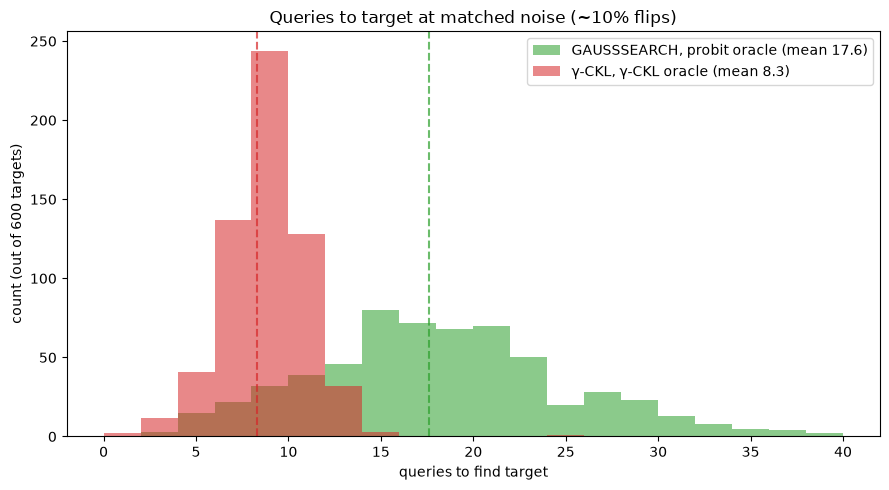

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
gs = results[("gauss", "probit")]
gc = results[("gckl", "gckl")]
bins = np.arange(0, max(gc.max(), gs.max()) + 3, 2)
ax.hist(gs, bins=bins, alpha=0.55, label=f"GAUSSSEARCH, probit oracle (mean {gs.mean():.1f})", color="tab:green")
ax.hist(gc, bins=bins, alpha=0.55, label=f"γ-CKL, γ-CKL oracle (mean {gc.mean():.1f})", color="tab:red")
ax.axvline(gs.mean(), color="tab:green", ls="--", alpha=0.7)
ax.axvline(gc.mean(), color="tab:red", ls="--", alpha=0.7)
ax.set_xlabel("queries to find target")
ax.set_ylabel("count (out of 600 targets)")
ax.set_title("Queries to target at matched noise (~10% flips)")
ax.legend()
plt.tight_layout()
plt.show()

γ-CKL's distribution is both lower and much tighter (p90 11 vs 27, max 24 vs 38).

## 5. Matched-noise sweep

The old Section 5 swept γ for the γ-CKL oracle while GAUSSSEARCH kept σ = 0.05, so the noise level of the comparison moved with γ. Here both oracles are re-tuned to the **same** flip rate at every level, and each algorithm runs under its own oracle with its user model set to that oracle's parameter. 26% is the noise of the old γ = 5 setting. 200 targets per level (every third image), seeds `60_000 + t`.

In [6]:
FLIP_LEVELS = [0.05, 0.10, 0.20, 0.26]
SWEEP_TARGETS = np.arange(0, n, 3)

sweep = {}
for f in FLIP_LEVELS:
    s = calibrate(flip_probit, f, 1e-3, 1e2, increasing=True)
    g = calibrate(flip_gckl, f, 0.1, 500.0, increasing=False)
    gs_q = [run_search("gauss", "probit", X, int(t), 60_000 + int(t), s, g)["n_queries"] for t in tqdm(SWEEP_TARGETS, leave=False)]
    gc_q = [run_search("gckl", "gckl", X, int(t), 60_000 + int(t), s, g)["n_queries"] for t in tqdm(SWEEP_TARGETS, leave=False)]
    sweep[f] = {"sigma": s, "gamma": g, "gauss": np.array(gs_q), "gckl": np.array(gc_q)}

print(f"{'flips':>6} | {'sigma':>6} {'gamma':>6} | {'GAUSS mean':>10} {'γ-CKL mean':>10} | {'ratio':>6} | {'GAUSS capped':>12}")
print("-" * 75)
for f in FLIP_LEVELS:
    r = sweep[f]
    print(f"{100*f:>5.0f}% | {r['sigma']:>6.3f} {r['gamma']:>6.2f} | {r['gauss'].mean():>10.2f} {r['gckl'].mean():>10.2f} "
          f"| {r['gckl'].mean()/r['gauss'].mean():>6.2f} | {int((r['gauss'] >= MAX_Q).sum()):>12d}")

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

 flips |  sigma  gamma | GAUSS mean γ-CKL mean |  ratio | GAUSS capped
---------------------------------------------------------------------------
    5% |  0.226  42.57 |      14.55       7.79 |   0.53 |            0
   10% |  0.461  19.89 |      16.68       8.20 |   0.49 |            0
   20% |  1.020   7.85 |      24.55      10.23 |   0.42 |            0
   26% |  1.478   4.94 |      31.93      13.22 |   0.41 |            0


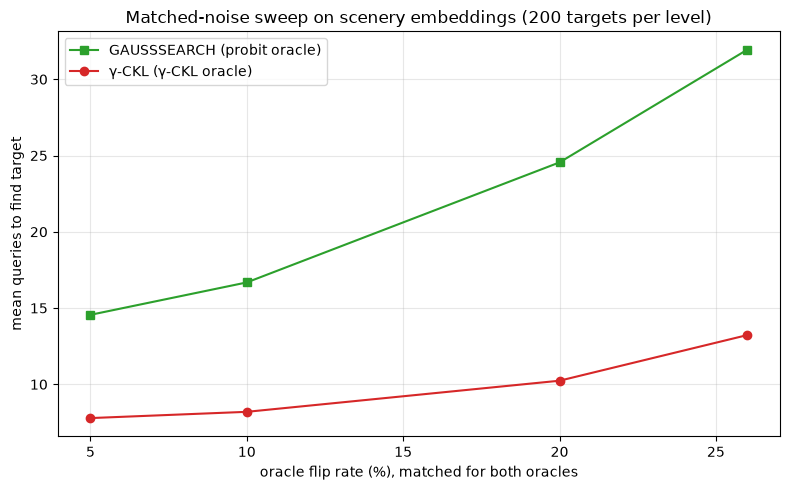

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
xs = [100 * f for f in FLIP_LEVELS]
ax.plot(xs, [sweep[f]["gauss"].mean() for f in FLIP_LEVELS], "s-", label="GAUSSSEARCH (probit oracle)", color="tab:green")
ax.plot(xs, [sweep[f]["gckl"].mean() for f in FLIP_LEVELS], "o-", label="γ-CKL (γ-CKL oracle)", color="tab:red")
ax.set_xlabel("oracle flip rate (%), matched for both oracles")
ax.set_ylabel("mean queries to find target")
ax.set_title("Matched-noise sweep on scenery embeddings (200 targets per level)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS / "matched_noise_sweep_scenery.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:**

| flips | σ | γ | GAUSS mean | γ-CKL mean | ratio |
|---|---|---|---|---|---|
| 5% | 0.226 | 42.6 | 14.55 | 7.79 | 0.53 |
| 10% | 0.461 | 19.9 | 16.68 | 8.20 | 0.49 |
| 20% | 1.020 | 7.85 | 24.55 | 10.23 | 0.42 |
| 26% | 1.478 | 4.94 | 31.93 | 13.22 | 0.41 |

γ-CKL is faster at every matched noise level, and the gap widens as the oracle gets noisier (ratio 0.53 at 5% down to 0.41 at 26%). No search hits the 200-query cap. The old sweep's GAUSS numbers at small γ were inflated by the mismatch between a σ = 0.05 user model and a 26%-noise oracle, not by the noise itself.

## 6. Per-class breakdown (own oracle, ~10% flips)

In [8]:
print(f"{'class':<12} {'n':>4} | {'GAUSS mean':>10} {'γ-CKL mean':>10} | {'ratio':>6}")
print("-" * 52)
gs = results[("gauss", "probit")]
gc = results[("gckl", "gckl")]
for cls in CLASSES:
    m = labels == cls
    print(f"{cls:<12} {m.sum():>4d} | {gs[m].mean():>10.2f} {gc[m].mean():>10.2f} | {gc[m].mean()/gs[m].mean():>6.2f}")

class           n | GAUSS mean γ-CKL mean |  ratio
----------------------------------------------------
buildings     100 |      16.47       7.88 |   0.48
forest        100 |      18.77       8.31 |   0.44
glacier       100 |      19.18       8.75 |   0.46
mountain      100 |      17.77       9.35 |   0.53
sea           100 |      16.78       8.02 |   0.48
street        100 |      16.57       7.54 |   0.46


**Observation:** the advantage is uniform across classes (ratio 0.44 to 0.53). Mountain is the hardest class for γ-CKL (9.35) and glacier for GAUSSSEARCH (19.18). The old per-class table compared γ-CKL with GAUSS under the γ-CKL oracle at γ = 5, so it was not an own-oracle comparison.

## 7. Class concentration

Replaces the old six-trace "lock" table. That table had one search per class, and its "buildings locks at step 0" was only the argmax of the uniform prior (index 0 is a buildings image), so it did not measure anything.

Here, at every step, I take the share of the two shown images that belong to the target's class, and average it over the searches **still running** at that step. Averaging only over running searches avoids crediting the faster algorithm for searches that are already over. Steps with fewer than 30 running searches are not drawn. Chance level is 1/6.

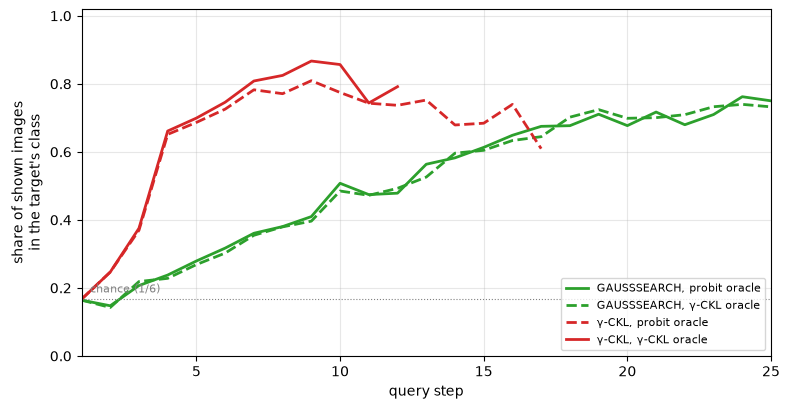

gauss | probit  share at step 1,4,6,10: [0.16, 0.24, 0.32, 0.51]   running at step 10,15,20: [528, 402, 223]
gauss | gckl    share at step 1,4,6,10: [0.16, 0.23, 0.3, 0.48]   running at step 10,15,20: [530, 397, 229]
 gckl | probit  share at step 1,4,6,10: [0.17, 0.65, 0.73, 0.77]   running at step 10,15,20: [275, 57, 19]
 gckl | gckl    share at step 1,4,6,10: [0.17, 0.66, 0.75, 0.86]   running at step 10,15,20: [164, 3, 1]


In [9]:
HORIZON = 25
MIN_RUNNING = 30
conc, running = {}, {}
for key in CELLS:
    s, c = np.zeros(HORIZON), np.zeros(HORIZON)
    for same in same_by_cell[key]:
        for k, v in enumerate(same[:HORIZON]):
            s[k] += v / 2.0
            c[k] += 1
    conc[key], running[key] = s / np.maximum(c, 1), c

style = {("gauss", "probit"): ("GAUSSSEARCH, probit oracle", "tab:green", "-"),
         ("gauss", "gckl"): ("GAUSSSEARCH, γ-CKL oracle", "tab:green", "--"),
         ("gckl", "probit"): ("γ-CKL, probit oracle", "tab:red", "--"),
         ("gckl", "gckl"): ("γ-CKL, γ-CKL oracle", "tab:red", "-")}
steps = np.arange(1, HORIZON + 1)
fig, ax = plt.subplots(figsize=(8, 4.2))
for key, (lab, col, ls) in style.items():
    m = running[key] >= MIN_RUNNING
    ax.plot(steps[m], conc[key][m], ls, color=col, lw=2, label=lab)
ax.axhline(1 / 6, color="gray", lw=0.8, ls=":")
ax.text(1.3, 1 / 6 + 0.02, "chance (1/6)", fontsize=8, color="gray")
ax.set_xlabel("query step")
ax.set_ylabel("share of shown images\nin the target's class")
ax.set_ylim(0, 1.02); ax.set_xlim(1, HORIZON)
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(PLOTS / "class_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

for key in CELLS:
    print(f"{key[0]:>5} | {key[1]:<6}  share at step 1,4,6,10: "
          f"{[round(float(conc[key][s - 1]), 2) for s in (1, 4, 6, 10)]}   "
          f"running at step 10,15,20: {[int(running[key][s - 1]) for s in (10, 15, 20)]}")

**Observation:** both start at chance (about 1/6). γ-CKL shows about **2/3** target-class images by step 4 and about **3/4** by step 6, under either oracle. GAUSSSEARCH is at about 1/4 by step 4 and 1/3 by step 6, and reaches 1/2 only around step 10. So γ-CKL does concentrate on the target's class within a few queries, while GAUSSSEARCH drifts towards it slowly; this is the averaged version of the "GAUSS feels random" observation. The γ-CKL curves stop early because few of its searches are still running after step 10 to 15.

### Illustration: one γ-CKL search per class (γ = 20, own oracle)

Kept as a picture of what a single search looks like, not as evidence; the curve above is the evidence. The argmax class is now taken from the posterior **after** each answer (the old version printed the prior's argmax, which made step 0 look like a lock).

In [10]:
picked_per_class = {}
for t in range(n):
    picked_per_class.setdefault(labels[t], t)

traces = {}
for cls in CLASSES:
    t = picked_per_class[cls]
    r = run_search("gckl", "gckl", X, t, 12_345 + t, SIGMA, GAMMA, trace=True)
    traces[cls] = r
    print(f"=== {cls} (target idx {t}): {'found' if r['found'] else 'NOT found'} in {r['n_queries']} queries")
    for k, rec in enumerate(r["trace"]):
        i, j = rec["i"], rec["j"]
        hit = "  <-- target shown" if t in (i, j) else ""
        print(f"   step {k:2d}: A={labels[i]:<10} B={labels[j]:<10} picked {'AB'[rec['y']]} "
              f"| P[target]={rec['P_target']:.4f}  argmax after={labels[rec['argmax_after']]:<10}{hit}")

=== buildings (target idx 0): found in 6 queries
   step  0: A=mountain   B=buildings  picked B | P[target]=0.0041  argmax after=buildings 
   step  1: A=forest     B=buildings  picked B | P[target]=0.0071  argmax after=buildings 
   step  2: A=buildings  B=street     picked A | P[target]=0.0133  argmax after=buildings 
   step  3: A=buildings  B=buildings  picked A | P[target]=0.0409  argmax after=buildings 
   step  4: A=street     B=buildings  picked A | P[target]=0.0758  argmax after=street    
   step  5: A=street     B=buildings  picked B | P[target]=0.0758  argmax after=street      <-- target shown
=== forest (target idx 100): found in 7 queries
   step  0: A=mountain   B=buildings  picked B | P[target]=0.0031  argmax after=buildings 
   step  1: A=forest     B=buildings  picked A | P[target]=0.0073  argmax after=street    
   step  2: A=forest     B=street     picked A | P[target]=0.0127  argmax after=buildings 
   step  3: A=forest     B=sea        picked A | P[target]=0.0207 

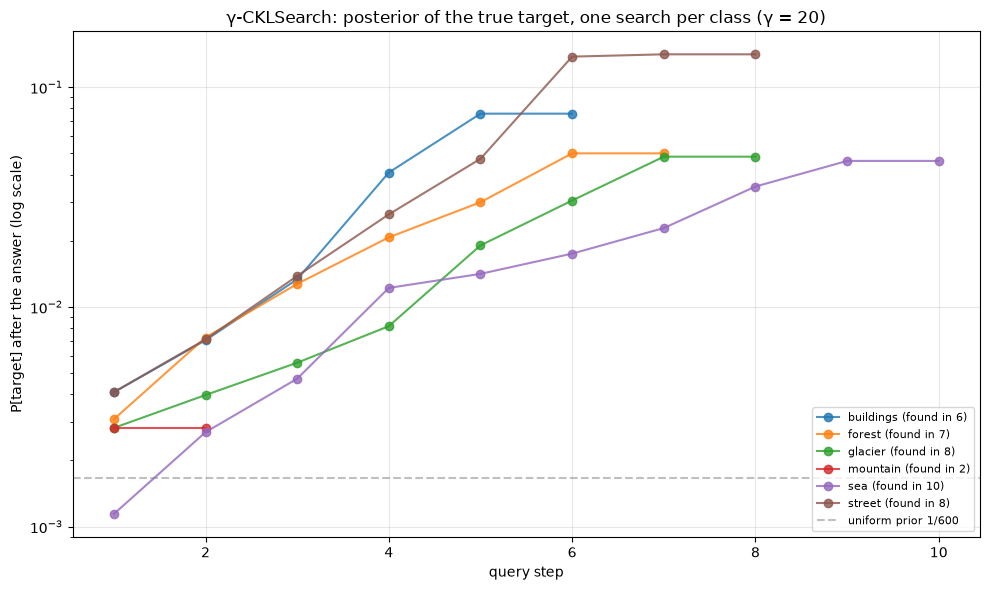

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
for cls in CLASSES:
    tr = traces[cls]["trace"]
    ax.plot(range(1, len(tr) + 1), [rec["P_target"] for rec in tr], "o-",
            label=f"{cls} (found in {traces[cls]['n_queries']})", alpha=0.8)
ax.axhline(1 / n, color="gray", ls="--", alpha=0.5, label=f"uniform prior 1/{n}")
ax.set_yscale("log")
ax.set_xlabel("query step")
ax.set_ylabel("P[target] after the answer (log scale)")
ax.set_title("γ-CKLSearch: posterior of the true target, one search per class (γ = 20)")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DATA / "gamma_ckl_convergence_per_class.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Save results

In [12]:
import pickle

out_path = DATA / "gamma_ckl_scenery_results.pkl"
with out_path.open("wb") as f:
    pickle.dump({
        "matched_2x2": {f"{a}|{k}": v.tolist() for (a, k), v in results.items()},
        "sigma_eps": SIGMA, "gamma": GAMMA,
        "flip_probit": flip_probit(SIGMA), "flip_gckl": flip_gckl(GAMMA),
        "sweep": {f: {"sigma": r["sigma"], "gamma": r["gamma"],
                      "gauss": r["gauss"].tolist(), "gckl": r["gckl"].tolist()} for f, r in sweep.items()},
        "sweep_targets": SWEEP_TARGETS.tolist(),
        "concentration": {f"{a}|{k}": conc[(a, k)].tolist() for (a, k) in CELLS},
        "still_running": {f"{a}|{k}": running[(a, k)].tolist() for (a, k) in CELLS},
        "n": n, "d": d, "X_scale": X_scale,
    }, f)
print(f"saved to {out_path}")

saved to ..\data\gamma_ckl_scenery_results.pkl
